# 01 Raw Data Analysis

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("../data/raw")
RESULTS = Path("../results")
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CUTOFF = pd.Timestamp("2017-03-31")
summary, raw = {}, {}  # summary: headline numbers, raw: distributions for the website


def counts(s, top=None):
    v = s.value_counts().sort_index() if top is None else s.value_counts().head(top)
    return {"labels": [str(k) for k in v.index], "values": [int(x) for x in v.values]}


def hist(x, edges):
    h, _ = np.histogram(x, bins=edges)
    return {"edges": [float(e) for e in edges], "values": [int(v) for v in h]}

## Target Tables

train_data: shape (946686, 2), unique msno 946,686, duplicated msno 0, missing 0
kaggle_test_data: shape (24274, 1), unique msno 24,274, duplicated msno 0, missing 0
overlap between train and test: 0
is_churn
renewed    861539
churned     85147
Name: count, dtype: int64
churn rate 0.0899


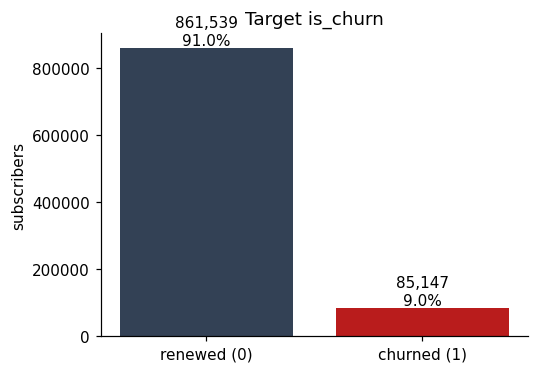

In [2]:
train = pd.read_csv(RAW / "train_data.csv")
test = pd.read_csv(RAW / "kaggle_test_data.csv")
for name, d in [("train_data", train), ("kaggle_test_data", test)]:
    print(f"{name}: shape {d.shape}, unique msno {d.msno.nunique():,}, duplicated msno {d.msno.duplicated().sum()}, missing {d.isna().sum().sum()}")
print(f"overlap between train and test: {len(set(train.msno) & set(test.msno))}")
print(train.is_churn.value_counts().rename({0: "renewed", 1: "churned"}))
print(f"churn rate {train.is_churn.mean():.4f}")

train = train.drop_duplicates("msno", keep="last")
users = set(train.msno)
summary["train"] = {"subscribers": len(train), "churners": int(train.is_churn.sum()), "churn_rate": round(float(train.is_churn.mean()), 5)}
summary["kaggle_test"] = {"subscribers": int(test.msno.nunique())}

fig, ax = plt.subplots(figsize=(5, 3.5))
vc = train.is_churn.value_counts().sort_index()
ax.bar(["renewed (0)", "churned (1)"], vc.values, color=["#334155", "#B91C1C"])
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v:,}\n{v / len(train):.1%}", ha="center", va="bottom")
ax.set(title="Target is_churn", ylabel="subscribers")
plt.tight_layout(); plt.savefig(FIG / "raw_target.png"); plt.show()

## Members

In [3]:
members = pd.read_csv(RAW / "members.csv", dtype={"gender": "string"})
print(members.dtypes, "\n")
print(f"rows {len(members):,} | unique msno {members.msno.nunique():,} | duplicated rows {members.duplicated().sum()}")
print("missing per column:\n", members.isna().sum())
members.describe()

msno                              object
city                               int64
bd                                 int64
gender                    string[python]
registered_via                     int64
registration_init_time             int64
dtype: object 



rows 6,769,473 | unique msno 6,769,473 | duplicated rows 0


missing per column:
 msno                            0
city                            0
bd                              0
gender                    4429505
registered_via                  0
registration_init_time          0
dtype: int64


,city,bd,registered_via,registration_init_time
count,6.769473e+06,6.769473e+06,6.769473e+06,6.769473e+06
mean,3.847358e+00,9.795794e+00,5.253069e+00,2.014518e+07
std,5.478359e+00,1.792590e+01,2.361398e+00,2.318601e+04
min,1.000000e+00,-7.168000e+03,-1.000000e+00,2.004033e+07
25%,1.000000e+00,0.000000e+00,4.000000e+00,2.014042e+07
50%,1.000000e+00,0.000000e+00,4.000000e+00,2.015101e+07
75%,4.000000e+00,2.100000e+01,7.000000e+00,2.016060e+07
max,2.200000e+01,2.016000e+03,1.900000e+01,2.017043e+07


In [4]:
bd = members.bd
age_checks = {"age 0 (not given)": int((bd == 0).sum()), "age negative": int((bd < 0).sum()),
              "age 1-9": int(bd.between(1, 9).sum()), "age 91+": int((bd > 90).sum()), "age 10-90 (valid)": int(bd.between(10, 90).sum())}
print(pd.Series(age_checks).to_string())
reg = pd.to_datetime(members.registration_init_time.astype(str), format="%Y%m%d", errors="coerce")
print(f"\nregistration dates {reg.min().date()} to {reg.max().date()}, after cutoff: {(reg > CUTOFF).sum():,}")
print(f"train subscribers with a profile: {train.msno.isin(members.msno).mean():.1%}")

summary["members"] = {"rows": len(members), "cols": members.shape[1],
                      "age_invalid_pct": round(float((~bd.between(10, 90)).mean()) * 100, 1),
                      "gender_blank_pct": round(float(members.gender.isna().mean()) * 100, 1),
                      "train_coverage_pct": round(float(train.msno.isin(members.msno).mean()) * 100, 1)}
raw["age"] = hist(bd[bd.between(10, 90)], np.arange(10, 95, 5))
raw["age_checks"] = age_checks
raw["gender"] = counts(members.gender.fillna("blank"))
raw["city"] = counts(members.city)
raw["registered_via"] = counts(members.registered_via)
raw["reg_year"] = counts(reg.dt.year.astype("Int64"))

age 0 (not given)    4540215
age negative             274
age 1-9                  899
age 91+                 7720
age 10-90 (valid)    2220365



registration dates 2004-03-26 to 2017-04-29, after cutoff: 55,094
train subscribers with a profile: 88.7%


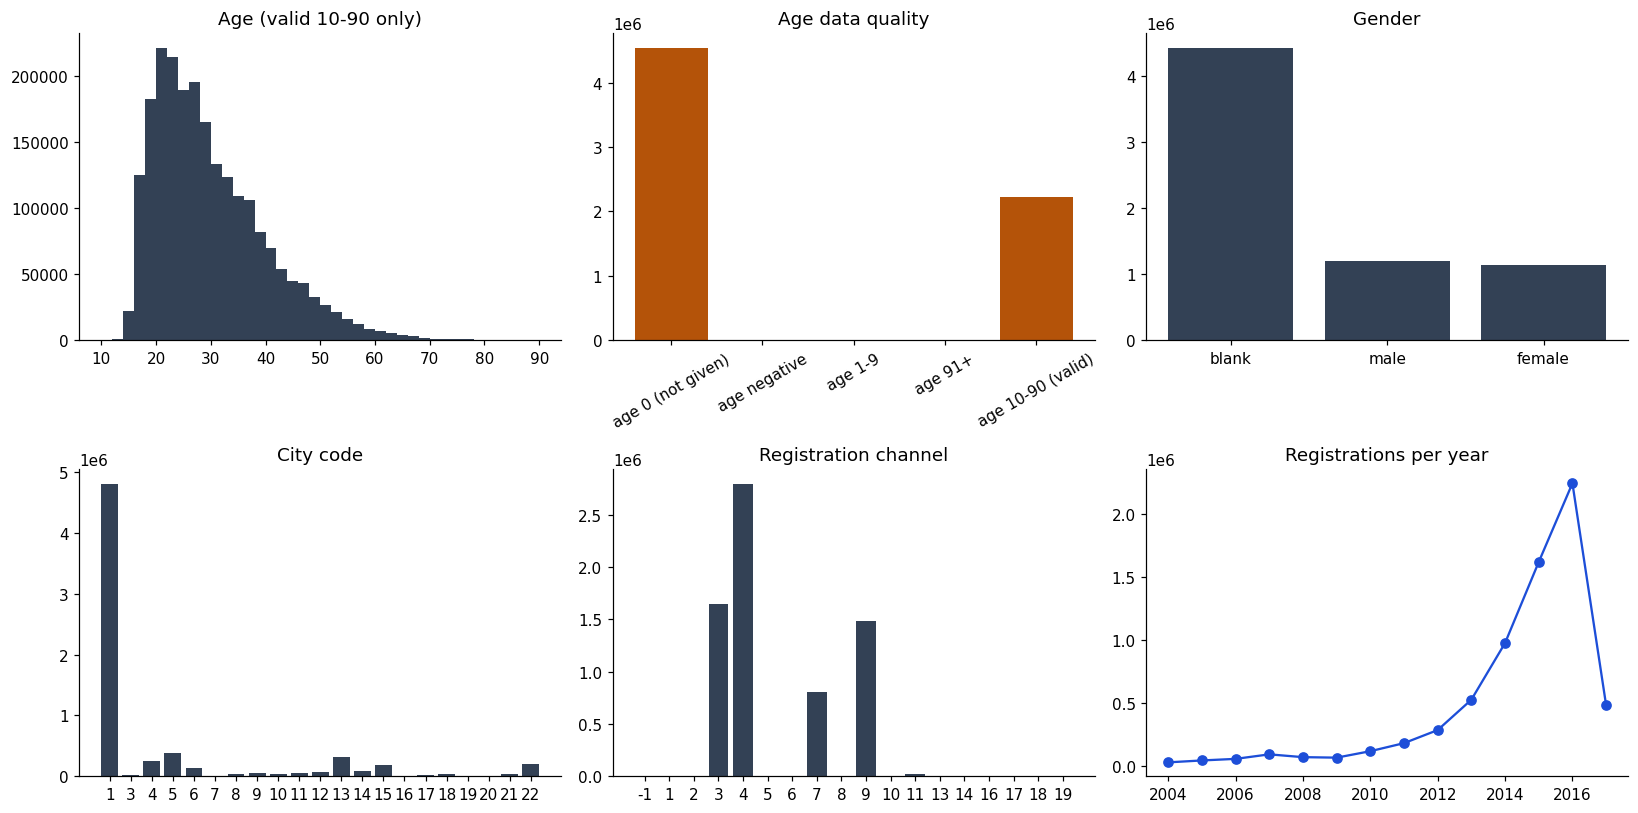

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
ax[0, 0].hist(bd[bd.between(10, 90)], bins=40, color="#334155"); ax[0, 0].set(title="Age (valid 10-90 only)")
ax[0, 1].bar(list(age_checks), list(age_checks.values()), color="#B45309"); ax[0, 1].set(title="Age data quality"); ax[0, 1].tick_params(axis="x", rotation=30)
g = members.gender.fillna("blank").value_counts(); ax[0, 2].bar(g.index, g.values, color="#334155"); ax[0, 2].set(title="Gender")
c = members.city.value_counts().sort_index(); ax[1, 0].bar(c.index.astype(str), c.values, color="#334155"); ax[1, 0].set(title="City code")
r = members.registered_via.value_counts().sort_index(); ax[1, 1].bar(r.index.astype(str), r.values, color="#334155"); ax[1, 1].set(title="Registration channel")
y = reg.dt.year.value_counts().sort_index(); ax[1, 2].plot(y.index, y.values, "o-", color="#1D4ED8"); ax[1, 2].set(title="Registrations per year")
plt.tight_layout(); plt.savefig(FIG / "raw_members.png"); plt.show()

## Members vs Churn

In [6]:
m = train.merge(members, on="msno", how="left")
m["age_group"] = pd.cut(m.bd.where(m.bd.between(10, 90)), [9, 20, 25, 30, 40, 90]).astype(str)
m["has_profile"] = m.city.notna()
for col in ["has_profile", "gender", "age_group", "registered_via"]:
    print(m.groupby(col, dropna=False).is_churn.agg(n="size", churn_rate="mean").round(3), "\n")
del members, m

                  n  churn_rate
has_profile                    
False        107153       0.053
True         839533       0.095 

             n  churn_rate
gender                    
female  179796       0.130
male    199439       0.129
<NA>    567451       0.064 

                n  churn_rate
age_group                    
(20, 25]    91451       0.153
(25, 30]    99010       0.109
(30, 40]   102126       0.108
(40, 90]    43811       0.098
(9, 20]     40436       0.246
nan        569852       0.062 

                     n  churn_rate
registered_via                    
3.0             103790       0.172
4.0              51424       0.231
7.0             451178       0.045
9.0             229833       0.127
13.0              3308       0.099
NaN             107153       0.053 



## Transactions

In [7]:
tx = pd.read_csv(RAW / "transactions.csv")
print(tx.dtypes, "\n")
print(f"rows {len(tx):,} | subscribers {tx.msno.nunique():,} | duplicated rows {tx.duplicated().sum()}")
print("missing per column:\n", tx.isna().sum())
tx.describe()

msno                      object
payment_method_id          int64
payment_plan_days          int64
plan_list_price            int64
actual_amount_paid         int64
is_auto_renew              int64
transaction_date           int64
membership_expire_date     int64
is_cancel                  int64
dtype: object 



rows 1,431,009 | subscribers 1,197,050 | duplicated rows 0
missing per column:
 msno                      0
payment_method_id         0
payment_plan_days         0
plan_list_price           0
actual_amount_paid        0
is_auto_renew             0
transaction_date          0
membership_expire_date    0
is_cancel                 0
dtype: int64


,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
count,1.431009e+06,1.431009e+06,1.431009e+06,1.431009e+06,1.431009e+06,1.431009e+06,1.431009e+06,1.431009e+06
mean,3.791835e+01,6.601770e+01,2.817870e+02,2.813172e+02,7.853025e-01,2.016848e+07,2.017110e+07,2.455121e-02
std,4.964805e+00,1.024864e+02,4.351861e+02,4.354200e+02,4.106124e-01,4.858797e+03,3.032367e+03,1.547529e-01
min,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.015010e+07,2.016042e+07,0.000000e+00
25%,3.600000e+01,3.000000e+01,9.900000e+01,9.900000e+01,1.000000e+00,2.017023e+07,2.017041e+07,0.000000e+00
50%,4.000000e+01,3.000000e+01,1.490000e+02,1.490000e+02,1.000000e+00,2.017031e+07,2.017042e+07,0.000000e+00
75%,4.100000e+01,3.000000e+01,1.490000e+02,1.490000e+02,1.000000e+00,2.017032e+07,2.017050e+07,0.000000e+00
max,4.100000e+01,4.500000e+02,2.000000e+03,2.000000e+03,1.000000e+00,2.017033e+07,2.036102e+07,1.000000e+00


In [8]:
tx["transaction_date"] = pd.to_datetime(tx.transaction_date.astype(str), format="%Y%m%d")
tx["membership_expire_date"] = pd.to_datetime(tx.membership_expire_date.astype(str), format="%Y%m%d")
checks = {"paid 0": int((tx.actual_amount_paid == 0).sum()), "list price 0": int((tx.plan_list_price == 0).sum()),
          "paid below list price": int((tx.actual_amount_paid < tx.plan_list_price).sum()),
          "expiry before transaction": int((tx.membership_expire_date < tx.transaction_date).sum()),
          "plan days 0": int((tx.payment_plan_days == 0).sum())}
print(pd.Series(checks).to_string())
print(f"\ndates {tx.transaction_date.min().date()} to {tx.transaction_date.max().date()}")
print(f"auto-renew {tx.is_auto_renew.mean():.1%} | cancel {tx.is_cancel.mean():.1%} of rows")
print(f"train subscribers with transactions: {train.msno.isin(tx.msno).mean():.1%}")

per_user = tx.groupby("msno").size()
summary["transactions"] = {"rows": len(tx), "cols": 9, "date_min": str(tx.transaction_date.min().date()),
                           "date_max": str(tx.transaction_date.max().date()),
                           "train_coverage_pct": round(float(train.msno.isin(tx.msno).mean()) * 100, 1)}
raw["tx_checks"] = checks
raw["plan_days"] = counts(tx.payment_plan_days, top=8)
raw["payment_method"] = counts(tx.payment_method_id, top=12)
raw["amount_paid"] = hist(tx.actual_amount_paid.clip(upper=2000), np.arange(0, 2050, 50))
raw["tx_per_user"] = counts(per_user.clip(upper=10))
raw["tx_month"] = counts(tx.transaction_date.dt.to_period("M").astype(str))
raw["auto_renew_share"] = float(tx.is_auto_renew.mean())
raw["cancel_share"] = float(tx.is_cancel.mean())

paid 0                       21448
list price 0                 18413
paid below list price         9639
expiry before transaction     5106
plan days 0                   2218

dates 2015-01-01 to 2017-03-31
auto-renew 78.5% | cancel 2.5% of rows


train subscribers with transactions: 96.1%


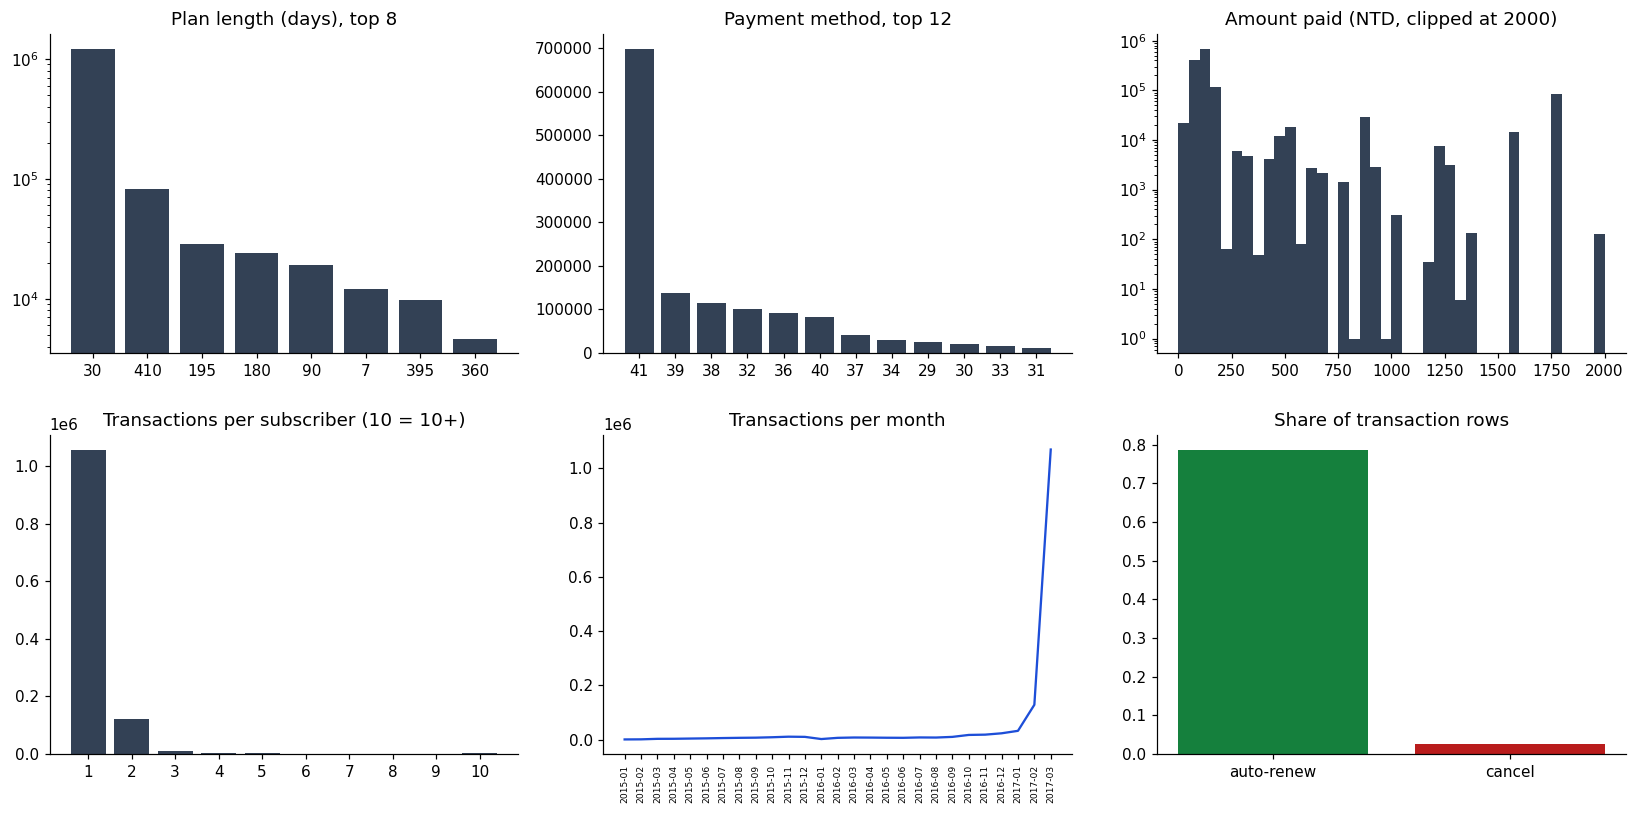

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
p = tx.payment_plan_days.value_counts().head(8); ax[0, 0].bar(p.index.astype(str), p.values, color="#334155"); ax[0, 0].set(title="Plan length (days), top 8", yscale="log")
pm = tx.payment_method_id.value_counts().head(12); ax[0, 1].bar(pm.index.astype(str), pm.values, color="#334155"); ax[0, 1].set(title="Payment method, top 12")
ax[0, 2].hist(tx.actual_amount_paid.clip(upper=2000), bins=40, color="#334155"); ax[0, 2].set(title="Amount paid (NTD, clipped at 2000)", yscale="log")
t = per_user.clip(upper=10).value_counts().sort_index(); ax[1, 0].bar(t.index.astype(str), t.values, color="#334155"); ax[1, 0].set(title="Transactions per subscriber (10 = 10+)")
mo = tx.transaction_date.dt.to_period("M").value_counts().sort_index(); ax[1, 1].plot(mo.index.astype(str), mo.values, color="#1D4ED8"); ax[1, 1].set(title="Transactions per month"); ax[1, 1].tick_params(axis="x", rotation=90, labelsize=6)
ax[1, 2].bar(["auto-renew", "cancel"], [tx.is_auto_renew.mean(), tx.is_cancel.mean()], color=["#15803D", "#B91C1C"]); ax[1, 2].set(title="Share of transaction rows")
plt.tight_layout(); plt.savefig(FIG / "raw_transactions.png"); plt.show()

## Transactions vs Churn

In [10]:
last = tx.sort_values(["msno", "transaction_date", "membership_expire_date"]).groupby("msno").tail(1)
t = train.merge(last, on="msno", how="left")
t["expiry_vs_cutoff"] = pd.cut((t.membership_expire_date - CUTOFF).dt.days, [-np.inf, -1, 30, 60, np.inf],
                               labels=["expired", "0-30 days", "31-60 days", "60+ days"]).astype(str)
for col in ["is_auto_renew", "is_cancel", "expiry_vs_cutoff"]:
    print(t.groupby(col, dropna=False).is_churn.agg(n="size", churn_rate="mean").round(3), "\n")
del tx, last, t, per_user

                    n  churn_rate
is_auto_renew                    
0.0             80829       0.307
1.0            829405       0.038
NaN             36452       0.787 

                n  churn_rate
is_cancel                    
0.0        891166       0.044
1.0         19068       0.909
NaN         36452       0.787 

                       n  churn_rate
expiry_vs_cutoff                    
0-30 days         792510       0.018
31-60 days         77922       0.054
60+ days           24404       0.944
expired            15398       0.955
nan                36452       0.787 



## User Logs

In [11]:
cols = ["msno", "date", "num_25", "num_50", "num_75", "num_985", "num_100", "num_unq", "total_secs"]
n_rows, bad_secs, log_users, rows_per_day = 0, 0, set(), pd.Series(0, index=range(1, 32))
plays = pd.Series(0, index=["num_25", "num_50", "num_75", "num_985", "num_100"], dtype="int64")
hours_edges, songs_edges = np.arange(0, 24.5, 0.5), np.arange(0, 205, 5)
hours_hist, songs_hist = np.zeros(len(hours_edges) - 1, int), np.zeros(len(songs_edges) - 1, int)
for chunk in pd.read_csv(RAW / "user_logs.csv", usecols=cols, chunksize=3_000_000):
    if n_rows == 0:
        print(chunk.dtypes, "\n"); print(chunk.describe().round(1), "\n")
    n_rows += len(chunk)
    bad_secs += int(((chunk.total_secs < 0) | (chunk.total_secs > 86_400)).sum())
    log_users.update(chunk.msno.unique())
    rows_per_day = rows_per_day.add((chunk.date - 20170300).value_counts(), fill_value=0)
    plays += chunk[plays.index].sum()
    hours_hist += np.histogram(chunk.total_secs.clip(0, 86_400) / 3600, bins=hours_edges)[0]
    songs_hist += np.histogram(chunk[plays.index].sum(axis=1).clip(upper=200), bins=songs_edges)[0]

print(f"rows {n_rows:,} | subscribers {len(log_users):,} | dates 1-31 March 2017")
print(f"rows with total_secs outside [0, 86400]: {bad_secs:,}")
print(f"train subscribers with March logs: {train.msno.isin(log_users).mean():.1%}")

summary["user_logs"] = {"rows": n_rows, "cols": 9, "bad_secs_rows": bad_secs,
                        "train_coverage_pct": round(float(train.msno.isin(log_users).mean()) * 100, 1)}
raw["log_rows_per_day"] = {"labels": [str(d) for d in rows_per_day.index], "values": [int(v) for v in rows_per_day.values]}
raw["daily_hours"] = {"edges": hours_edges.tolist(), "values": hours_hist.tolist()}
raw["daily_songs"] = {"edges": songs_edges.tolist(), "values": songs_hist.tolist()}
raw["play_depth"] = {"labels": ["< 25 %", "25-50 %", "50-75 %", "75-98.5 %", "98.5-100 %"], "values": [int(v) for v in plays.values]}

msno           object
date            int64
num_25          int64
num_50          int64
num_75          int64
num_985         int64
num_100         int64
num_unq         int64
total_secs    float64
dtype: object 



             date     num_25     num_50     num_75    num_985    num_100  \
count   3000000.0  3000000.0  3000000.0  3000000.0  3000000.0  3000000.0   
mean   20170316.1        6.2        1.5        0.9        1.1       30.3   
std           8.9       13.2        3.9        1.9        3.5       40.3   
min    20170301.0        0.0        0.0        0.0        0.0        0.0   
25%    20170308.0        0.0        0.0        0.0        0.0        7.0   
50%    20170316.0        2.0        1.0        0.0        0.0       17.0   
75%    20170324.0        7.0        2.0        1.0        1.0       37.0   
max    20170331.0     3799.0      558.0      340.0      957.0     5216.0   

         num_unq  total_secs  
count  3000000.0   3000000.0  
mean        29.1      7905.7  
std         32.2      9751.7  
min          1.0         0.0  
25%          8.0      1961.1  
50%         18.0      4587.2  
75%         38.0      9840.0  
max       3547.0   1233169.7   



rows 18,396,362 | subscribers 1,103,894 | dates 1-31 March 2017
rows with total_secs outside [0, 86400]: 4,200


train subscribers with March logs: 77.7%


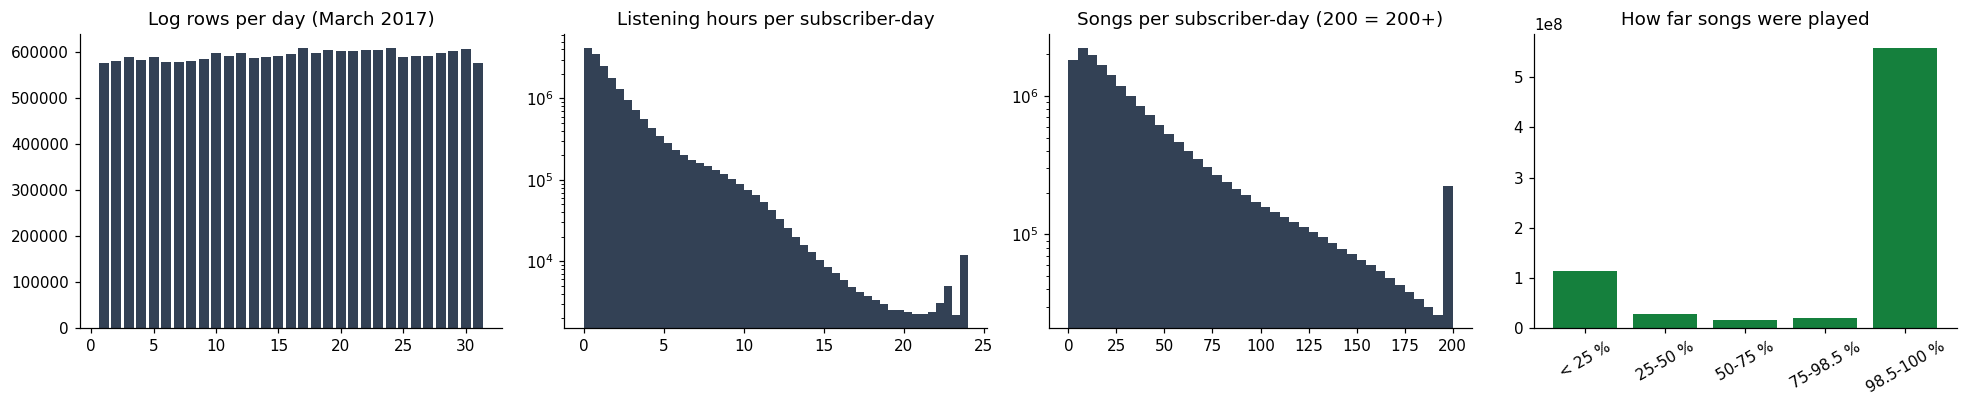

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].bar(rows_per_day.index, rows_per_day.values, color="#334155"); ax[0].set(title="Log rows per day (March 2017)")
ax[1].bar(hours_edges[:-1], hours_hist, width=0.5, align="edge", color="#334155"); ax[1].set(title="Listening hours per subscriber-day", yscale="log")
ax[2].bar(songs_edges[:-1], songs_hist, width=5, align="edge", color="#334155"); ax[2].set(title="Songs per subscriber-day (200 = 200+)", yscale="log")
ax[3].bar(raw["play_depth"]["labels"], plays.values, color="#15803D"); ax[3].set(title="How far songs were played"); ax[3].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "raw_user_logs.png"); plt.show()

## Table Coverage

 profile  transactions  logs      n  churn_rate
   False         False False   1725    0.989565
   False         False  True      5    1.000000
   False          True False 105410    0.038023
   False          True  True     13    0.307692
    True         False False   6623    0.978258
    True         False  True  28099    0.729385
    True          True False  97180    0.071887
    True          True  True 707631    0.064247


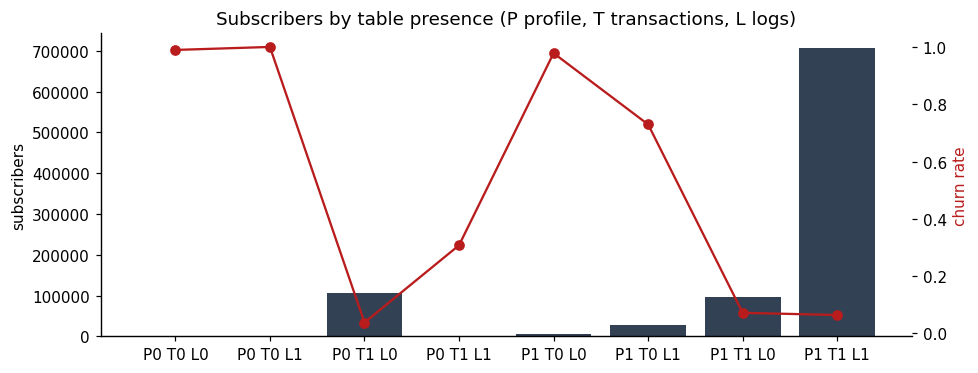

In [13]:
mem_ids = set(pd.read_csv(RAW / "members.csv", usecols=["msno"]).msno)
tx_ids = set(pd.read_csv(RAW / "transactions.csv", usecols=["msno"]).msno)
cov = pd.DataFrame({"profile": train.msno.isin(mem_ids), "transactions": train.msno.isin(tx_ids),
                    "logs": train.msno.isin(log_users), "is_churn": train.is_churn.values})
combo = cov.groupby(["profile", "transactions", "logs"]).is_churn.agg(n="size", churn_rate="mean").reset_index()
print(combo.to_string(index=False))
raw["coverage"] = combo.assign(n=combo.n.astype(int)).to_dict(orient="records")

fig, ax = plt.subplots(figsize=(9, 3.5))
lab = combo.apply(lambda r: f"P{int(r.profile)} T{int(r.transactions)} L{int(r.logs)}", axis=1)
ax.bar(lab, combo.n, color="#334155"); ax2 = ax.twinx(); ax2.plot(lab, combo.churn_rate, "o-", color="#B91C1C")
ax.set(title="Subscribers by table presence (P profile, T transactions, L logs)", ylabel="subscribers"); ax2.set_ylabel("churn rate", color="#B91C1C")
plt.tight_layout(); plt.savefig(FIG / "raw_coverage.png"); plt.show()

In [14]:
(RESULTS / "data_summary.json").write_text(json.dumps(summary, indent=1, default=float))
(RESULTS / "raw_summary.json").write_text(json.dumps(raw, default=float))
print("saved results/data_summary.json and results/raw_summary.json")

saved results/data_summary.json and results/raw_summary.json
